# Setup, Go Mechanics, and KataGo Engine Interface

In [1]:
import csv
import json
from pathlib import Path
import subprocess
import sys
import threading
import time

import matplotlib.pyplot as plt
import numpy as np

# ==================== GLOBAL CONFIGURATION ====================
BOARD_SIZE = 19
LETTERS = "ABCDEFGHJKLMNOPQRST"  # Standard GTP coordinate letters (excluding 'I')
KOMI = 7.5

VISITS_BASE = 100
VISITS_PERTURB = 10

# Configure KataGo binaries and configuration files
KATAGO = Path(
    r"C:\Users\39342\Desktop\GO\katago-v1.16.4-cuda12.8-cudnn9.8.0-windows-x64\katago.exe"
)
MODEL = Path(
    r"C:\Users\39342\Desktop\GO\katago-v1.16.4-cuda12.8-cudnn9.8.0-windows-x64\model.bin.gz"
)
CONFIG = Path(
    r"C:\Users\39342\Desktop\GO\katago-v1.16.4-cuda12.8-cudnn9.8.0-windows-x64\analysis_example.cfg"
)

for p in [KATAGO, MODEL, CONFIG]:
    assert p.exists(), f"File not found: {p}"

# ==================== ENGINE SUBPROCESS ====================
engine = subprocess.Popen(
    [str(KATAGO), "analysis", "-config", str(CONFIG), "-model", str(MODEL)],
    stdin=subprocess.PIPE,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
    bufsize=1,
    universal_newlines=True,
    cwd=str(KATAGO.parent),
)


def monitor_stderr():
    for line in engine.stderr:
        print("KATAGO ERR:", line.strip(), file=sys.stderr, flush=True)
        if "Started, ready" in line:
            engine.stderr_ready = True


engine.stderr_ready = False
threading.Thread(target=monitor_stderr, daemon=True).start()

startup_timeout = 15
start_time = time.time()
while time.time() - start_time < startup_timeout:
    if engine.poll() is not None:
        raise RuntimeError("KataGo crashed during initialization.")
    if getattr(engine, "stderr_ready", False):
        break
    time.sleep(0.1)
else:
    engine.kill()
    raise RuntimeError("KataGo failed to initialize within 15 seconds.")

print("KataGo engine successfully initialized.")


# ==================== ENGINE QUERY & BOARD UTILITIES ====================
def query_katago(moves, player_next="B", max_visits=100):
    """Sends an analysis query to the KataGo engine via JSON interface."""
    query = {
        "id": f"q_{time.time_ns()}",
        "boardXSize": BOARD_SIZE,
        "boardYSize": BOARD_SIZE,
        "moves": moves,
        "rules": "japanese",
        "komi": KOMI,
        "includeOwnership": True,
        "includePolicy": True,
        "maxVisits": max_visits,
        "overrideSettings": {"reportAnalysisWinratesAs": player_next},
    }
    engine.stdin.write(json.dumps(query) + "\n")
    engine.stdin.flush()

    while True:
        if engine.poll() is not None:
            raise RuntimeError("KataGo terminated unexpectedly during query.")
        line = engine.stdout.readline()
        if not line:
            time.sleep(0.01)
            continue
        line = line.strip()
        if line.startswith("{"):
            data = json.loads(line)
            if data.get("id") == query["id"]:
                return data


def gtp_to_xy(gtp):
    """Converts a GTP coordinate string (e.g., 'Q4') to zero-indexed board coordinates (x, y)."""
    col = LETTERS.index(gtp[0].upper())
    row = BOARD_SIZE - int(gtp[1:])
    return col, row


def moves_to_board(moves):
    """Reconstructs the 19x19 board state, resolving group captures sequentially."""
    board = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=int)
    for col_str, gtp in moves:
        x, y = gtp_to_xy(gtp)
        color = 1 if col_str == "B" else -1
        board[y, x] = color
        opp = -color

        # Check for opponent captures along the four cardinal directions
        for nx, ny in [(x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)]:
            if 0 <= nx < BOARD_SIZE and 0 <= ny < BOARD_SIZE and board[ny, nx] == opp:
                group = []
                stack = [(nx, ny)]
                visited = {(nx, ny)}
                liberties = 0

                while stack:
                    cx, cy = stack.pop()
                    group.append((cx, cy))
                    for nnx, nny in [
                        (cx + 1, cy),
                        (cx - 1, cy),
                        (cx, cy + 1),
                        (cx, cy - 1),
                    ]:
                        if 0 <= nnx < BOARD_SIZE and 0 <= nny < BOARD_SIZE:
                            if board[nny, nnx] == 0:
                                liberties += 1
                            elif (
                                board[nny, nnx] == opp
                                and (nnx, nny) not in visited
                            ):
                                visited.add((nnx, nny))
                                stack.append((nnx, nny))

                if liberties == 0:
                    for gx, gy in group:
                        board[gy, gx] = 0
    return board


# ==================== SPATIAL DECOMPOSITION ====================
def get_liberties(board, group):
    """Extracts empty adjacent points (liberties) of a given stone group."""
    liberties = set()
    for x, y in group["stones"]:
        for nx, ny in [(x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)]:
            if (
                0 <= nx < BOARD_SIZE
                and 0 <= ny < BOARD_SIZE
                and board[ny, nx] == 0
            ):
                liberties.add((nx, ny))
    return liberties


def find_groups(board):
    """Detects connected components of stones on the board."""
    visited = np.zeros_like(board, dtype=bool)
    groups = []
    for y in range(BOARD_SIZE):
        for x in range(BOARD_SIZE):
            if board[y, x] == 0 or visited[y, x]:
                continue
            color = board[y, x]
            stack = [(x, y)]
            visited[y, x] = True
            stones = []
            while stack:
                cx, cy = stack.pop()
                stones.append((cx, cy))
                for nx, ny in [
                    (cx + 1, cy),
                    (cx - 1, cy),
                    (cx, cy + 1),
                    (cx, cy - 1),
                ]:
                    if (
                        0 <= nx < BOARD_SIZE
                        and 0 <= ny < BOARD_SIZE
                        and not visited[ny, nx]
                        and board[ny, nx] == color
                    ):
                        visited[ny, nx] = True
                        stack.append((nx, ny))
            groups.append({"color": color, "stones": stones, "type": "group"})
    return groups


def fragment_component(own_heatmap, cells, merge_thresh):
    """Performs agglomerative clustering on disputed regions based on ownership gradients."""
    zones = [
        {"cells": [(x, y)], "own": float(own_heatmap[y, x])} for x, y in cells
    ]

    while len(zones) > 1:
        min_diff = float("inf")
        pair = None

        cell_to_zone = {
            (x, y): i for i, z in enumerate(zones) for x, y in z["cells"]
        }

        for i, zi in enumerate(zones):
            neighbors = set()
            for x, y in zi["cells"]:
                for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                    nxy = (x + dx, y + dy)
                    if nxy in cell_to_zone and cell_to_zone[nxy] != i:
                        neighbors.add(cell_to_zone[nxy])

            for j in neighbors:
                if j > i:
                    diff = abs(zi["own"] - zones[j]["own"])
                    if diff < min_diff:
                        min_diff = diff
                        pair = (i, j)

        if pair is None or min_diff > merge_thresh:
            break

        i, j = pair
        n_i, n_j = len(zones[i]["cells"]), len(zones[j]["cells"])
        merged_own = (zones[i]["own"] * n_i + zones[j]["own"] * n_j) / (
            n_i + n_j
        )
        zones[i]["cells"].extend(zones[j]["cells"])
        zones[i]["own"] = merged_own
        zones.pop(j)

    return zones


def find_contested_zones(
    board, ownership, own_thresh=0.75, merge_thresh=0.2, min_size=2
):
    """Identifies vacant regions with intermediate territory ownership."""
    mask = (
        (board == 0)
        & (np.abs(ownership) < own_thresh)
        & (np.abs(ownership) > 0.05)
    )
    if not np.any(mask):
        return []

    h, w = mask.shape
    visited = np.zeros_like(mask, dtype=bool)
    components = []

    for y in range(h):
        for x in range(w):
            if mask[y, x] and not visited[y, x]:
                cells = []
                stack = [(x, y)]
                while stack:
                    cx, cy = stack.pop()
                    if (
                        not (0 <= cx < w and 0 <= cy < h)
                        or visited[cy, cx]
                        or not mask[cy, cx]
                    ):
                        continue
                    visited[cy, cx] = True
                    cells.append((cx, cy))
                    for dx, dy in [(-1, 0), (0, -1), (0, 1), (1, 0)]:
                        stack.append((cx + dx, cy + dy))
                if len(cells) >= min_size:
                    components.append(cells)

    final_zones = []
    for comp in components:
        subzones = fragment_component(ownership, comp, merge_thresh)
        final_zones.extend(
            [z for z in subzones if len(z["cells"]) >= min_size]
        )

    return [
        {"color": 0, "stones": z["cells"], "type": "zone"} for z in final_zones
    ]


def find_all_nodes(board, base_own):
    """Extracts all strategic entities (stone groups and contested territorial zones)."""
    nodes = []
    for g in find_groups(board):
        stones = g["stones"]
        nodes.append({
            "type": "group",
            "stones": stones,
            "color": g["color"],
            "own": np.mean([base_own[gy, gx] for gx, gy in stones]),
        })

    zones = find_contested_zones(board, base_own)
    nodes.extend(zones)
    return nodes


def feature_node(board, ownership, node):
    """Extracts local tactical potential for a group (liberties) or zone (ownership)."""
    if node["type"] == "group":
        libs = get_liberties(board, node)
        vals = (
            np.array([ownership[y, x] for x, y in node["stones"]])
            if not libs
            else np.array([ownership[ny, nx] for nx, ny in libs])
        )
        return np.mean(vals) if node["color"] == 1 else np.mean(-vals)
    return np.mean([ownership[y, x] for x, y in node["stones"]])


# Warm-up query
_ = query_katago([], "B", 10)
print("KataGo warm-up completed.")

KATAGO ERR: 2026-09-14 13:10:45+0200: Running with following config:
KATAGO ERR: nnCacheSizePowerOfTwo = 20
KATAGO ERR: nnMaxBatchSize = 32
KATAGO ERR: nnMutexPoolSizePowerOfTwo = 18
KATAGO ERR: numAnalysisThreads = 2
KATAGO ERR: numSearchThreads = 8
KATAGO ERR: 
KATAGO ERR: 2026-09-14 13:10:45+0200: Analysis Engine starting...
KATAGO ERR: 2026-09-14 13:10:45+0200: KataGo v1.16.4
KATAGO ERR: 2026-09-14 13:10:45+0200: nnRandSeed0 = 16589511990316980181
KATAGO ERR: 2026-09-14 13:10:45+0200: After dedups: nnModelFile0 = C:\Users\39342\Desktop\GO\katago-v1.16.4-cuda12.8-cudnn9.8.0-windows-x64\model.bin.gz useFP16 auto useNHWC auto
KATAGO ERR: 2026-09-14 13:10:45+0200: Initializing neural net buffer to be size 19 * 19 allowing smaller boards
KATAGO ERR: 2026-09-14 13:10:46+0200: Cuda backend thread 0: Found GPU NVIDIA GeForce RTX 4090 memory 25756696576 compute capability major 8 minor 9
KATAGO ERR: 2026-09-14 13:10:46+0200: Cuda backend thread 0: Model version 14 useFP16 = true useNHWC = t

KataGo engine successfully initialized.
KataGo warm-up completed.


# Dependency Matrix, Spectral Tension, and Tension Profile Example

Loaded: 2ipv-gokifu-20160310-Lee_Sedol-AlphaGo.sgf | Total plies: 210
Ply   2 | Tension:  0.1512 | Groups:  2 | Zones:  7
Ply   3 | Tension:  0.4286 | Groups:  3 | Zones: 10
Ply   4 | Tension:  1.1474 | Groups:  4 | Zones:  7
Ply   5 | Tension:  0.5956 | Groups:  5 | Zones: 11
Ply   6 | Tension:  1.1381 | Groups:  6 | Zones: 12
Ply   7 | Tension:  0.7892 | Groups:  7 | Zones: 11
Ply   8 | Tension:  1.5684 | Groups:  7 | Zones: 10
Ply   9 | Tension:  0.8936 | Groups:  8 | Zones: 11
Ply  10 | Tension:  1.8891 | Groups:  9 | Zones: 14
Ply  11 | Tension:  1.4174 | Groups: 10 | Zones: 15
Ply  12 | Tension:  2.2640 | Groups: 11 | Zones: 13
Ply  13 | Tension:  3.0205 | Groups: 12 | Zones: 11
Ply  14 | Tension:  2.7107 | Groups: 13 | Zones: 17
Ply  15 | Tension:  2.0198 | Groups: 14 | Zones: 16
Ply  16 | Tension:  3.4556 | Groups: 13 | Zones: 15
Ply  17 | Tension:  2.6768 | Groups: 14 | Zones: 15
Ply  18 | Tension:  3.0375 | Groups: 15 | Zones: 14
Ply  19 | Tension:  2.5302 | Groups: 16 | Zone

Ply 160 | Tension:  2.0676 | Groups: 68 | Zones: 13
Ply 161 | Tension:  2.8958 | Groups: 68 | Zones: 12
Ply 162 | Tension:  2.6348 | Groups: 68 | Zones: 14
Ply 163 | Tension:  2.4369 | Groups: 68 | Zones: 15
Ply 164 | Tension:  3.0915 | Groups: 68 | Zones: 15
Ply 165 | Tension:  3.2630 | Groups: 69 | Zones: 17
Ply 166 | Tension:  2.7841 | Groups: 70 | Zones: 14
Ply 167 | Tension:  4.0234 | Groups: 70 | Zones: 13
Ply 168 | Tension:  3.7077 | Groups: 69 | Zones: 14
Ply 169 | Tension:  3.5911 | Groups: 67 | Zones: 13
Ply 170 | Tension:  3.5935 | Groups: 68 | Zones: 12
Ply 171 | Tension:  3.1410 | Groups: 68 | Zones: 11
Ply 172 | Tension:  2.9905 | Groups: 69 | Zones:  9
Ply 173 | Tension:  3.2732 | Groups: 69 | Zones: 10
Ply 174 | Tension:  3.0524 | Groups: 67 | Zones:  9
Ply 175 | Tension:  4.2623 | Groups: 68 | Zones:  8
Ply 176 | Tension:  3.2767 | Groups: 68 | Zones:  9
Ply 177 | Tension:  2.9700 | Groups: 68 | Zones:  8
Ply 178 | Tension:  2.8970 | Groups: 68 | Zones:  9
Ply 179 | Te

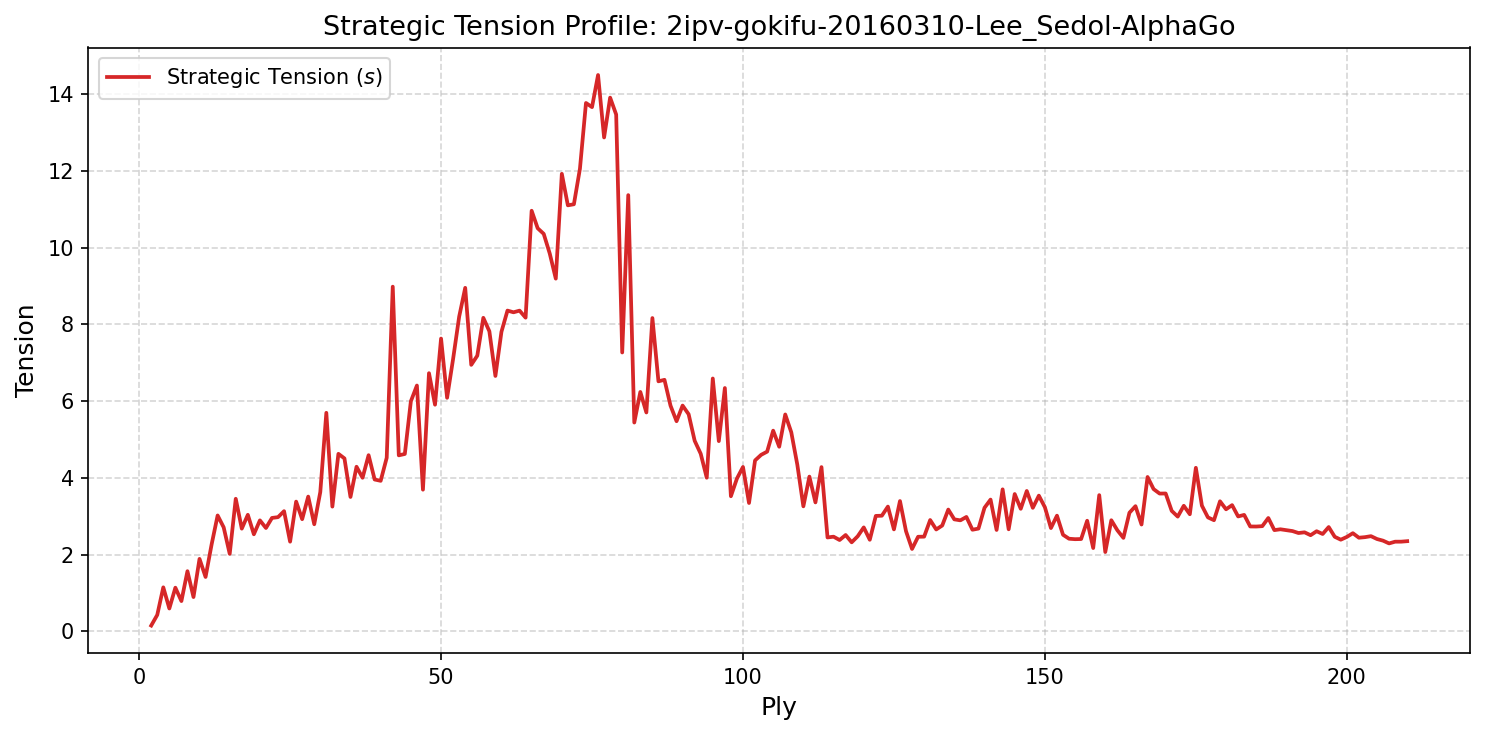

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sgfmill import sgf

# ==================== RUN CONFIGURATION ====================
SGF_FOLDER = Path(r"C:\Users\39342\Desktop\GO\SUPER_MATCH")
N_PERTURB = (
    1  # Sample size for candidate moves (set to None for all legal moves)
)
SAMPLE_STEP = 1  # Ply stride between successive tension calculations


def sgf_to_moves(sgf_path):
    """Parses a 19x19 SGF file into an ordered list of [color, GTP_coordinate]."""
    with open(sgf_path, "rb") as f:
        game = sgf.Sgf_game.from_bytes(f.read())
    if game.get_size() != BOARD_SIZE:
        return []

    moves = []
    for node in game.get_main_sequence():
        color, move = node.get_move()
        if color and move:
            row, col = move
            color_str = "B" if color == "b" else "W"
            gtp = f"{LETTERS[col]}{BOARD_SIZE - row}"
            moves.append([color_str, gtp])
    return moves


# Load the target game
sgf_file = next(SGF_FOLDER.glob("*.sgf"))
MOVES = sgf_to_moves(sgf_file)
print(f"Loaded: {sgf_file.name} | Total plies: {len(MOVES)}")


# ==================== TENSION LOAD FORMULATION ====================
def compute_dependency_matrix(moves, player_next):
    """Constructs the spatial interaction matrix W across groups and disputed zones."""
    board = moves_to_board(moves)
    res = query_katago(moves, player_next, VISITS_BASE)
    base_own = np.array(res["ownership"]).reshape(BOARD_SIZE, BOARD_SIZE)

    # Extract legal moves based on non-zero prior policy probabilities
    policy = np.array(res["policy"][:361]).reshape(BOARD_SIZE, BOARD_SIZE)
    legal = [
        (x, y)
        for y in range(BOARD_SIZE)
        for x in range(BOARD_SIZE)
        if policy[y, x] > 0
    ]
    num_legal = len(legal)

    # Characteristic spatial coupling scale
    l0 = np.sqrt(num_legal / np.pi)

    nodes = find_all_nodes(board, base_own)
    n = len(nodes)
    if n <= 1:
        return np.zeros((1, 1)), np.zeros((1, 1)), np.zeros((1, 1)), nodes

    f_before = np.array([feature_node(board, base_own, node) for node in nodes])
    dims = np.array([len(node["stones"]) for node in nodes])
    colors = np.array([node["color"] for node in nodes])
    types = [node["type"] for node in nodes]

    libs = np.array([
        max(1, len(get_liberties(board, nodes[i])))
        if types[i] == "group"
        else 1.0
        for i in range(n)
    ])

    # Minimum boundary distance (Manhattan metric) between entities
    dist_matrix = np.zeros((n, n))
    for i in range(n):
        s_i = np.array(nodes[i]["stones"])
        for j in range(i + 1, n):
            s_j = np.array(nodes[j]["stones"])
            if len(s_i) > 0 and len(s_j) > 0:
                dx = np.abs(s_i[:, None, 0] - s_j[None, :, 0])
                dy = np.abs(s_i[:, None, 1] - s_j[None, :, 1])
                min_d = np.min(dx + dy)
            else:
                min_d = 2 * BOARD_SIZE
            dist_matrix[i, j] = min_d
            dist_matrix[j, i] = min_d

    w_plot = np.zeros((n, n))
    w_signed = np.zeros((n, n))
    opp_player = "W" if player_next == "B" else "B"
    player_color = 1 if player_next == "B" else -1

    if N_PERTURB is None or N_PERTURB >= num_legal:
        test_moves = legal
    else:
        test_moves = [
            legal[i]
            for i in np.random.choice(num_legal, N_PERTURB, replace=False)
        ]

    valid_count = 0
    for x, y in test_moves:
        p_move = f"{LETTERS[x]}{BOARD_SIZE - y}"
        try:
            p_res = query_katago(
                moves + [[player_next, p_move]], opp_player, VISITS_PERTURB
            )
            own_after = np.array(p_res["ownership"]).reshape(
                BOARD_SIZE, BOARD_SIZE
            )
        except Exception:
            continue

        valid_count += 1
        raw_diff = np.array([
            feature_node(board, own_after, nodes[j]) - f_before[j]
            for j in range(n)
        ])
        delta = np.array([
            raw_diff[j]
            if types[j] != "group" or colors[j] == 1
            else -raw_diff[j]
            for j in range(n)
        ])

        for i in range(n):
            for j in range(i + 1, n):
                if types[i] == "zone" and types[j] == "zone":
                    continue

                # Effective susceptibility weights
                if types[i] == "group" and types[j] == "group":
                    eff_i, eff_j = 1.0 / libs[i], 1.0 / libs[j]
                elif types[i] == "group" and types[j] == "zone":
                    eff_i, eff_j = libs[i], (dims[j] ** 2) / BOARD_SIZE
                elif types[i] == "zone" and types[j] == "group":
                    eff_i, eff_j = (dims[i] ** 2) / BOARD_SIZE, libs[j]
                else:
                    continue

                geo_decay = np.exp(-dist_matrix[i, j] / l0)
                coupling_weight = (
                    np.sqrt(eff_i * eff_j) * geo_decay / BOARD_SIZE
                )
                interaction = coupling_weight * delta[i] * delta[j]

                w_plot[i, j] += interaction
                w_plot[j, i] += interaction

                if types[i] == "group" and types[j] == "group":
                    alliance = 1 if colors[i] == colors[j] else -1
                    actor = 1 if player_color == colors[i] else -1
                    signed_term = interaction * alliance * actor
                    w_signed[i, j] += signed_term
                    w_signed[j, i] += signed_term

    if valid_count > 0:
        w_plot /= valid_count
        w_signed /= valid_count

    return w_plot, w_signed, np.abs(w_plot), nodes


def calc_tension(w_abs):
    """Computes the spectral tension load as the largest eigenvalue of the interaction matrix."""
    if w_abs.size <= 1:
        return 0.0
    w_sym = w_abs + w_abs.T
    np.fill_diagonal(w_sym, 0)
    if np.allclose(w_sym, 0):
        return 0.0
    return float(np.max(np.abs(np.linalg.eigvalsh(w_sym))))


# ==================== MATCH ANALYSIS PIPELINE ====================
tension_profile = []
indices = list(range(2, len(MOVES) + 1, SAMPLE_STEP))
if len(MOVES) not in indices and len(MOVES) > 1:
    indices.append(len(MOVES))

for k in indices:
    current_moves = MOVES[:k]
    player_next = "W" if current_moves[-1][0] == "B" else "B"

    w_plot, w_signed, w_abs, nodes = compute_dependency_matrix(
        current_moves, player_next
    )
    tension_val = calc_tension(w_abs)

    num_groups = sum(1 for n in nodes if n["type"] == "group")
    num_zones = sum(1 for n in nodes if n["type"] == "zone")

    tension_profile.append({
        "move": k,
        "tension": tension_val,
        "groups": num_groups,
        "zones": num_zones,
    })
    print(
        f"Ply {k:3d} | Tension: {tension_val:7.4f} | Groups: {num_groups:2d} | Zones: {num_zones:2d}"
    )

# ==================== EXPORT RESULTS & VISUALIZATION ====================
with open("tension_profile.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f, fieldnames=["move", "tension", "groups", "zones"]
    )
    writer.writeheader()
    writer.writerows(tension_profile)

np.save("W_signed_last.npy", w_signed)
print("Data saved: 'tension_profile.csv' and 'W_signed_last.npy'.")

# Trajectory plotting
plies = [p["move"] for p in tension_profile]
tensions = [p["tension"] for p in tension_profile]

plt.figure(figsize=(10, 5), dpi=150)
plt.plot(
    plies,
    tensions,
    color="tab:red",
    linewidth=1.8,
    label="Strategic Tension ($s$)",
)
plt.xlabel("Ply", fontsize=12)
plt.ylabel("Tension", fontsize=12)
plt.title(f"Strategic Tension Profile: {sgf_file.stem}", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("tension_profile.png", dpi=300)
plt.show()